# till ML

In [5]:
from common import *
engine = get_engine()

In [6]:
ml=pd.read_sql(
    "SELECT * FROM silver.flights_clean",
    con=engine)

In [7]:
ml.head()

,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,DISTANCE,SCHEDULED_DEPARTURE,SCHEDULED_ARRIVAL,DEPARTURE_DELAY,...,WEATHER_SURFACE_PRESSURE,WEATHER_WIND_DIRECTION,WEATHER_SNOWFALL,WEATHER_WIND_GUSTS,YEAR,IS_DELAYED,FLIGHT_STATUS,IS_WEEKEND,DEPARTURE_PERIOD,IS_LONG_DISTANCE
0,October,15,4,B6,SJU,FLL,1046,12:33:00,15:12:00,0.0,...,1015.299988,90.0,0.0,20.200001,2015,0.0,Completed,0,Afternoon,0
1,January,10,6,DL,ATL,MDW,591,10:25:00,11:28:00,-3.0,...,994.400024,341.0,0.0,31.299999,2015,0.0,Completed,1,Morning,0
2,August,21,5,WN,ATL,LAX,1947,08:25:00,10:15:00,-1.0,...,981.200012,319.0,0.0,11.500000,2015,0.0,Completed,0,Morning,1
3,December,3,4,AA,CLT,BOS,728,09:40:00,11:51:00,-4.0,...,990.400024,324.0,0.0,24.100000,2015,0.0,Completed,0,Morning,0
4,July,21,2,WN,LAX,MDW,1750,16:45:00,22:40:00,21.0,...,1008.599976,200.0,0.0,14.000000,2015,0.0,Completed,0,Afternoon,1


##Addım 1. Ümumi uçuş statistikasını öyrənək

### 1.1 Ümumi Göstəricilər

In [8]:
total_flights = len(ml)
valid_target = ml["IS_DELAYED"].notna()

In [9]:
delayed_flights = (ml.loc[valid_target, "IS_DELAYED"] == 1).sum()
not_delayed_flights = (ml.loc[valid_target, "IS_DELAYED"] == 0).sum()

In [10]:
cancelled_flights = (ml["CANCELLED"] == 1).sum()
diverted_flights = (ml["DIVERTED"] == 1).sum()

In [11]:
summary = pd.DataFrame({
    "Göstərici": [
        "Ümumi uçuş sayı",
        "Gecikmə statusu məlum olan uçuşlar",
        "Gecikən uçuşlar",
        "Gecikməyən uçuşlar",
        "Ləğv edilən uçuşlar",
        "İstiqaməti dəyişdirilən uçuşlar"],
    "Say": [
        total_flights,
        valid_target.sum(),
        delayed_flights,
        not_delayed_flights,
        cancelled_flights,
        diverted_flights]})
print(summary,
    f"Gecikmə faizi: "
    f"{delayed_flights / valid_target.sum() * 100:.2f}%")


                            Göstərici     Say
0                     Ümumi uçuş sayı  999657
1  Gecikmə statusu məlum olan uçuşlar  981515
2                     Gecikən uçuşlar  182526
3                  Gecikməyən uçuşlar  798989
4                 Ləğv edilən uçuşlar   15527
5     İstiqaməti dəyişdirilən uçuşlar    2615 Gecikmə faizi: 18.60%


### 1.2 Gecikmə dəqiqələrinin statistikası

In [12]:
delay_comparison = ml[
    ["DEPARTURE_DELAY", "ARRIVAL_DELAY"]
].describe( percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).T

display(delay_comparison.round(2))


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
DEPARTURE_DELAY,984790.0,9.34,37.00,-47.0,-5.0,-2.0,7.0,35.0,67.0,168.0,1631.0
ARRIVAL_DELAY,981515.0,4.39,39.21,-82.0,-13.0,-5.0,8.0,34.0,66.0,166.0,1638.0


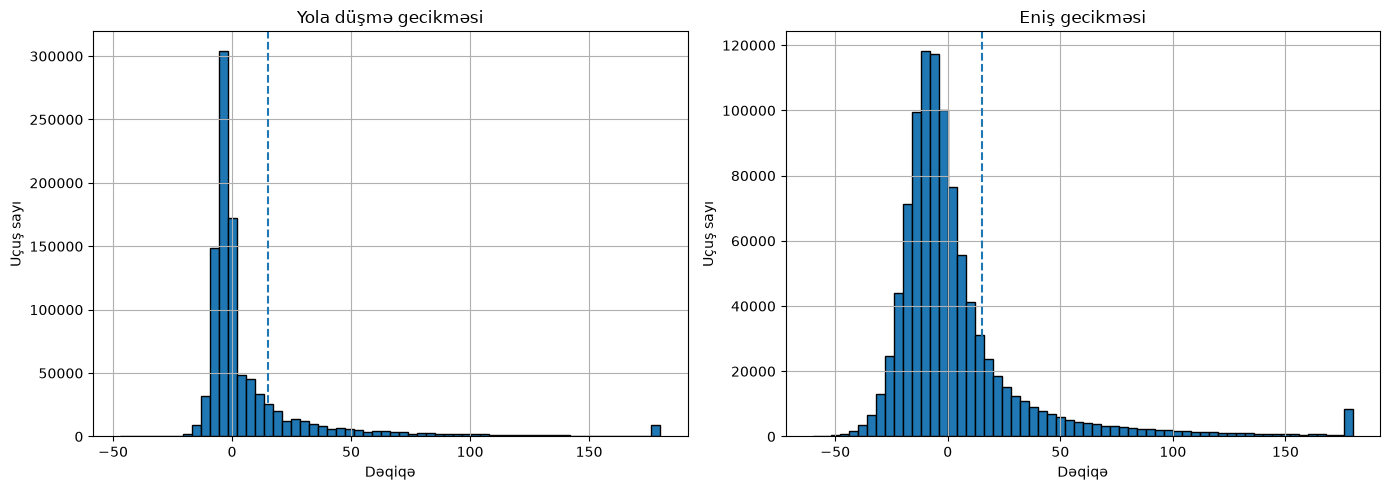

In [13]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ml["DEPARTURE_DELAY"].dropna().clip(-60, 180).hist(
    bins=60, ax=axes[0], edgecolor="black"
)
axes[0].axvline(15, linestyle="--")
axes[0].set_title("Yola düşmə gecikməsi")
axes[0].set_xlabel("Dəqiqə")
axes[0].set_ylabel("Uçuş sayı")

ml["ARRIVAL_DELAY"].dropna().clip(-60, 180).hist(
    bins=60, ax=axes[1], edgecolor="black"
)
axes[1].axvline(15, linestyle="--")
axes[1].set_title("Eniş gecikməsi")
axes[1].set_xlabel("Dəqiqə")
axes[1].set_ylabel("Uçuş sayı")

plt.tight_layout()
plt.show()


### Yola düşmə və eniş gecikmələrinin statistik təhlili

Yola düşmə və eniş gecikmələrinin təsviri statistikası uçuşların vaxtında yerinə yetirilməsi və gecikmələrin paylanması haqqında ilkin təsəvvür yaradır.

Analiz nəticələrinə əsasən, yola düşmə gecikməsinin orta qiyməti 9,34 dəqiqə, eniş gecikməsinin orta qiyməti isə 4,39 dəqiqədir. Bu fərq uçuşların orta hesabla təyinat yerinə yola düşmə gecikməsindən daha az gecikmə ilə çatdığını göstərir.

Hər iki göstəricinin medianı mənfidir: yola düşmə üçün −2 dəqiqə, eniş üçün −5 dəqiqə. Bu nəticə tipik uçuşun planlaşdırılmış vaxtdan daha tez həyata keçirildiyini göstərir. Orta qiymətlərin medianlardan yüksək olması isə böyük gecikmələrin paylanmaya təsir etdiyini göstərir.

Yola düşmə gecikməsinin standart deviation-u 37,00 dəqiqə, eniş gecikməsinin standart deviation-u isə 39,21 dəqiqədir. Bu göstəricilər uçuş vaxtlarındakı dəyişkənliyin yüksək olduğunu göstərir.

99-cu persentildə yola düşmə gecikməsi 168 dəqiqə, eniş gecikməsi isə 166 dəqiqədir. Maksimum gecikmələrin müvafiq olaraq 1 631 və 1 638 dəqiqə olması paylanmada ekstremal müşahidələrin mövcudluğunu göstərir.

Ümumilikdə, nəticələr gecikmə göstəricilərinin simmetrik paylanmadığını və az sayda böyük gecikmələrin orta qiymətə təsir etdiyini göstərir. Növbəti mərhələdə gecikmələr aviaşirkətlər, həftənin günləri, uçuş vaxtları və hava şəraiti üzrə müqayisə ediləcək.

##Addım 2 — aviaşirkətlər üzrə gecikmə analizi

### Addım 2.1. Aviaşirkətlər üzrə əsas göstəricilər

In [14]:

# Hədəf və gecikmə məlumatları mövcud olan uçuşlardan istifadə
airline_df = ml[ml["IS_DELAYED"].notna()].copy()

airline_stats = (
    airline_df.groupby(["AIRLINE", "AIRLINE_NAME"], dropna=False)
    .agg(
        TOTAL_FLIGHTS=("IS_DELAYED", "size"),
        DELAYED_FLIGHTS=("IS_DELAYED", "sum"),
        AVG_DEPARTURE_DELAY=("DEPARTURE_DELAY", "mean"),
        AVG_ARRIVAL_DELAY=("ARRIVAL_DELAY", "mean"),
        MEDIAN_DEPARTURE_DELAY=("DEPARTURE_DELAY", "median"),
        MEDIAN_ARRIVAL_DELAY=("ARRIVAL_DELAY", "median")).reset_index())

In [15]:
airline_stats["DELAY_RATE_%"] = (
    airline_stats["DELAYED_FLIGHTS"]
    / airline_stats["TOTAL_FLIGHTS"] * 100)

airline_stats = airline_stats.sort_values(
    "DELAY_RATE_%", ascending=False)

display(airline_stats.round(2))


,AIRLINE,AIRLINE_NAME,TOTAL_FLIGHTS,DELAYED_FLIGHTS,AVG_DEPARTURE_DELAY,AVG_ARRIVAL_DELAY,MEDIAN_DEPARTURE_DELAY,MEDIAN_ARRIVAL_DELAY,DELAY_RATE_%
8,NK,Spirit Air Lines,19944,5970.0,15.54,14.23,-1.0,0.0,29.93
5,F9,Frontier Airlines Inc.,15601,4190.0,13.45,12.73,-2.0,-1.0,26.86
2,B6,JetBlue Airways,44870,10107.0,11.17,6.52,-2.0,-5.0,22.53
7,MQ,American Eagle Airlines Inc.,47723,10200.0,10.01,6.54,-2.0,-6.0,21.37
10,UA,United Air Lines Inc.,87167,17904.0,14.26,5.33,1.0,-6.0,20.54
4,EV,Atlantic Southeast Airlines,95261,18710.0,8.71,6.66,-3.0,-4.0,19.64
12,VX,Virgin America,10594,2050.0,9.08,4.91,-1.0,-3.0,19.35
13,WN,Southwest Airlines Co.,214136,40773.0,10.53,4.39,0.0,-4.0,19.04
11,US,US Airways Inc.,33487,6326.0,6.18,3.77,-2.0,-4.0,18.89
9,OO,Skywest Airlines Inc.,98645,18380.0,7.76,5.83,-3.0,-4.0,18.63


Bu cədvəldə:
- TOTAL_FLIGHTS — aviaşirkətin uçuş sayı.
- DELAYED_FLIGHTS — 15 dəqiqəlik meyarına əsasən gecikən uçuşların sayı.
- DELAY_RATE_% — gecikən uçuşların faizi.
- AVG_DEPARTURE_DELAY və AVG_ARRIVAL_DELAY — orta yola düşmə və eniş gecikmələri.
- MEDIAN_... — ekstremal gecikmələrin təsirinə daha az həssas olan median göstəricilər.

### Addım 2.2. Gecikmə faizlərinin qrafiki

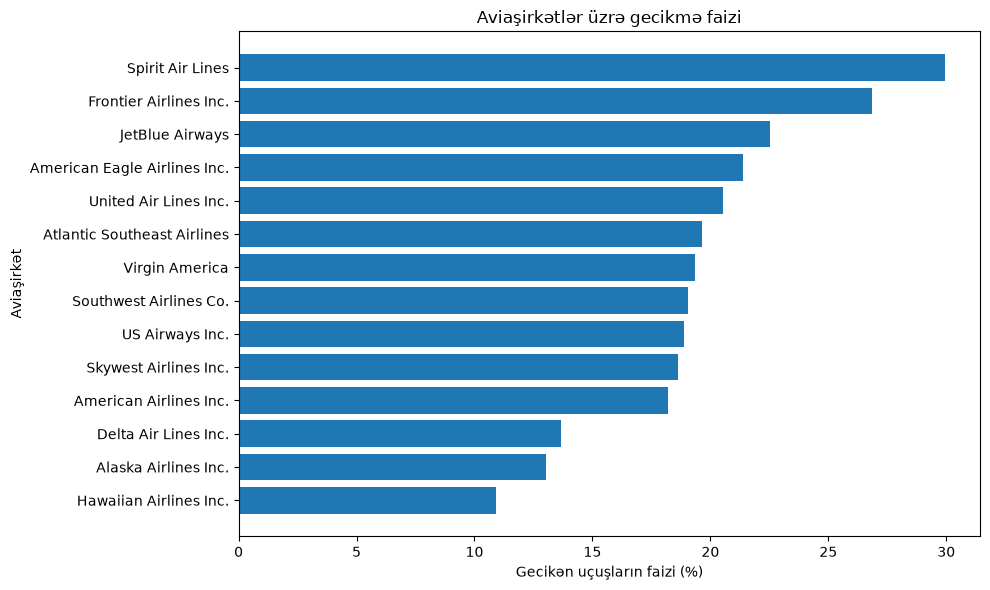

In [16]:
plot_df = airline_stats.sort_values("DELAY_RATE_%")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_df["AIRLINE_NAME"],
    plot_df["DELAY_RATE_%"]
)

plt.xlabel("Gecikən uçuşların faizi (%)")
plt.ylabel("Aviaşirkət")
plt.title("Aviaşirkətlər üzrə gecikmə faizi")
plt.tight_layout()
plt.show()


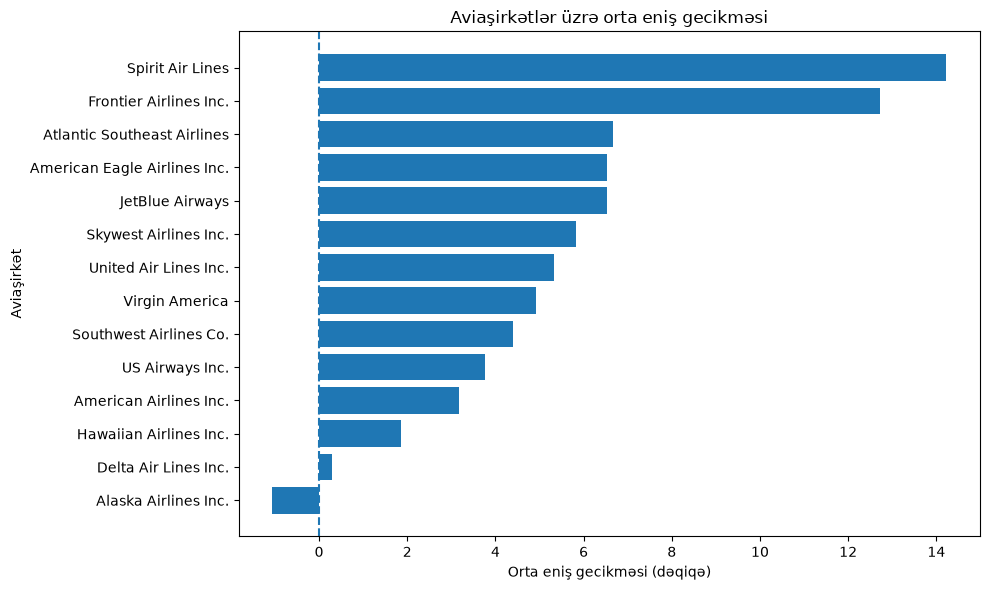

In [17]:

arrival_plot = airline_stats.sort_values(
    "AVG_ARRIVAL_DELAY"
)

plt.figure(figsize=(10, 6))
plt.barh(
    arrival_plot["AIRLINE_NAME"],
    arrival_plot["AVG_ARRIVAL_DELAY"]
)

plt.axvline(0, linestyle="--")
plt.xlabel("Orta eniş gecikməsi (dəqiqə)")
plt.ylabel("Aviaşirkət")
plt.title("Aviaşirkətlər üzrə orta eniş gecikməsi")
plt.tight_layout()
plt.show()


### Aviaşirkətlər üzrə gecikmə analizi — Nəticələr

- **Gecikmə faizinə görə:** Spirit Air Lines ən yüksək göstəriciyə malikdir — **29.93%**. Onu Frontier Airlines (**26.86%**) və JetBlue Airways (**22.53%**) izləyir.
- **Ən aşağı gecikmə faizi:** Hawaiian Airlines-da qeydə alınıb — **10.93%**. Alaska Airlines (**13.05%**) və Delta Air Lines (**13.65%**) də nisbətən aşağı göstəricilərə malikdir.
- **Orta gəliş gecikməsinə görə:** Spirit Air Lines (**14.23 dəqiqə**) və Frontier Airlines (**12.73 dəqiqə**) ən yüksək orta gecikmə müddətinə malik aviaşirkətlərdir.
- **Müsbət nəticə göstərən aviaşirkətlər:** Delta Air Lines-ın orta gəliş gecikməsi cəmi **0.28 dəqiqə**, Alaska Airlines-ın göstəricisi isə **-1.06 dəqiqədir**. Mənfi göstərici uçuşların orta hesabla planlaşdırılan vaxtdan tez çatdığını bildirir.
- **Uçuş sayının təsiri:** Southwest Airlines ən çox uçuşa (**214,136**) və ən çox gecikən uçuş sayına (**40,773**) malikdir. Lakin gecikmə faizi **19.04%** olduğuna görə ən yüksək gecikmə faizi olan aviaşirkət deyil.

**Ümumi nəticə:** Aviaşirkətlərin gecikmə göstəriciləri arasında nəzərəçarpan fərqlər mövcuddur. Spirit Air Lines və Frontier Airlines həm gecikmə faizi, həm də orta gəliş gecikməsi baxımından daha zəif nəticə göstərir. Buna baxmayaraq, bu fərqlər yalnız aviaşirkətin fəaliyyətindən qaynaqlanmaya bilər; hava şəraiti, uçuş marşrutları, hava limanlarının yüklənməsi və digər amillər də gecikmələrə təsir edə bilər. Bu amilləri növbəti mərhələlərdə araşdırmaq lazımdır.

##Addım 3. Həftənin günlərinə görə gecikmə analizi


###3.1 Günlər üzrə statistik göstəricilər

In [18]:
weekday_df = ml[ml["IS_DELAYED"].notna()].copy()

In [19]:
# Həftənin günlərinə görə statistika
weekday_stats = (
    weekday_df.groupby("DAY_OF_WEEK")
    .agg(
        TOTAL_FLIGHTS=("IS_DELAYED", "size"),
        DELAYED_FLIGHTS=("IS_DELAYED", "sum"),
        AVG_ARRIVAL_DELAY=("ARRIVAL_DELAY", "mean"),
        MEDIAN_ARRIVAL_DELAY=("ARRIVAL_DELAY", "median")).reset_index())

In [20]:
# Gecikmə faizinin hesablanması
weekday_stats["DELAY_RATE_%"] = (
    weekday_stats["DELAYED_FLIGHTS"]
    / weekday_stats["TOTAL_FLIGHTS"] * 100
)

In [21]:
day_names = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"}

weekday_stats["DAY_NAME"] = weekday_stats["DAY_OF_WEEK"].map(day_names)

In [22]:
weekday_stats = weekday_stats[[
        "DAY_OF_WEEK",
        "DAY_NAME",
        "TOTAL_FLIGHTS",
        "DELAYED_FLIGHTS",
        "DELAY_RATE_%",
        "AVG_ARRIVAL_DELAY",
        "MEDIAN_ARRIVAL_DELAY"]].sort_values("DAY_OF_WEEK")

display(weekday_stats.round(2))

,DAY_OF_WEEK,DAY_NAME,TOTAL_FLIGHTS,DELAYED_FLIGHTS,DELAY_RATE_%,AVG_ARRIVAL_DELAY,MEDIAN_ARRIVAL_DELAY
0,1,Monday,144778,28418.0,19.63,5.84,-5.0
1,2,Tuesday,142076,25957.0,18.27,4.30,-5.0
2,3,Wednesday,144945,26558.0,18.32,3.85,-5.0
3,4,Thursday,147476,29423.0,19.95,5.65,-4.0
4,5,Friday,145792,28166.0,19.32,4.94,-4.0
5,6,Saturday,118274,18984.0,16.05,1.76,-6.0
6,7,Sunday,138174,25020.0,18.11,3.83,-5.0


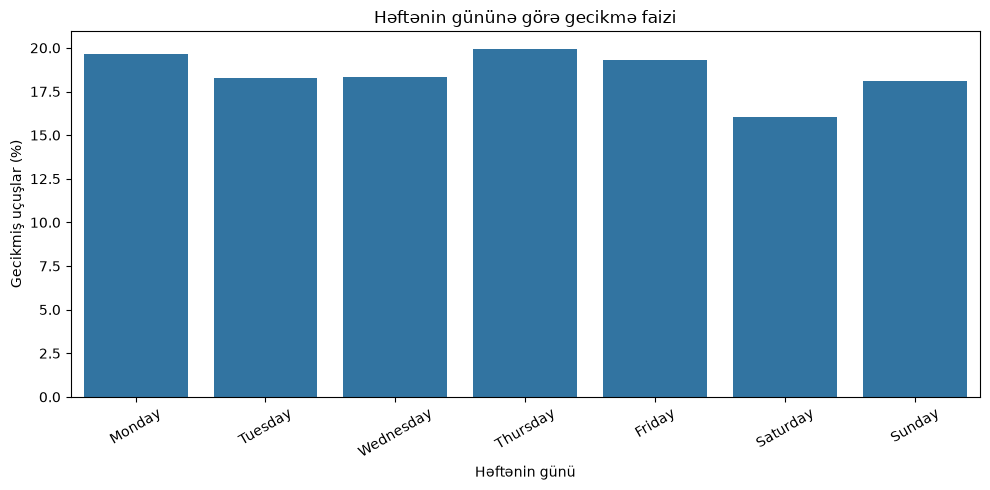

In [23]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_stats,
    x="DAY_NAME",
    y="DELAY_RATE_%")

plt.title("Həftənin gününə görə gecikmə faizi")
plt.xlabel("Həftənin günü")
plt.ylabel("Gecikmiş uçuşlar (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Gecikmə faizi (DELAY_RATE_%) — uçuşların neçə faizi ən azı 15 dəqiqə gec çatıb.

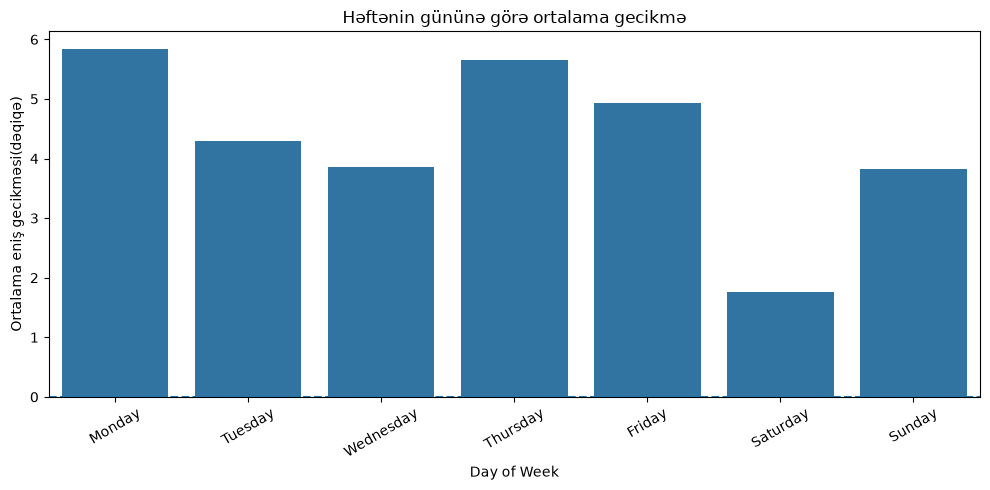

In [24]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=weekday_stats,
    x="DAY_NAME",
    y="AVG_ARRIVAL_DELAY"
)

plt.title("Həftənin gününə görə ortalama gecikmə")
plt.xlabel("Day of Week")
plt.ylabel("Ortalama eniş gecikməsi(dəqiqə)")
plt.axhline(0, linestyle="--")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Orta gəliş gecikməsi (AVG_ARRIVAL_DELAY) — bütün uçuşların gəliş gecikmələrinin orta müddəti, dəqiqə ilə.

### Həftənin günləri arasındakı gecikmə faizlərinin fərqini statistik testlə yoxlayaq. Beləliklə, gördüyümüz fərqlərin təsadüfi dəyişkənlikdən daha artıq olub-olmadığını qiymətləndirə bilərik.
Buna görə yeddi günün gecikmə faizlərini müqayisə etmək üçün Chi-square (χ²) müstəqillik testi uyğundur.


In [25]:
# Yalnız hədəf göstəricisi məlum olan uçuşlar
test_df = ml[ml["IS_DELAYED"].notna()].copy()

In [26]:
# Həftənin günü və gecikmə statusu üzrə tezlik cədvəli
contingency_table = pd.crosstab(
    test_df["DAY_OF_WEEK"],
    test_df["IS_DELAYED"])

In [27]:
# Chi-square testi
chi2, p_value, dof, expected = chi2_contingency(contingency_table)


In [28]:
# Cramer's V: əlaqənin gücünü qiymətləndirmək üçün
n = contingency_table.to_numpy().sum()
cramers_v = np.sqrt(
    chi2 / (n * min(contingency_table.shape[0] - 1,
                    contingency_table.shape[1] - 1))
)

print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6f}")
print(f"Cramer's V: {cramers_v:.4f}")

if p_value < 0.05:
    print("Nəticə: Həftənin günü ilə gecikmə statusu arasında statistik əhəmiyyətli əlaqə var.")
else:
    print("Nəticə: Statistik əhəmiyyətli əlaqə üçün kifayət qədər sübut yoxdur.")

Chi-square statistic: 876.2605
Degrees of freedom: 6
P-value: 0.000000
Cramer's V: 0.0299
Nəticə: Həftənin günü ilə gecikmə statusu arasında statistik əhəmiyyətli əlaqə var.


### Chi-square testi — Nəticələr və şərh

Həftənin günü ilə uçuşun gəliş gecikmə statusu arasındakı əlaqəni yoxlamaq üçün Chi-square müstəqillik testi aparılmışdır.

**Hipotezlər:**
- **H₀:** Həftənin günü ilə gecikmə statusu arasında əlaqə yoxdur.
- **H₁:** Həftənin günü ilə gecikmə statusu arasında əlaqə var.

**Test nəticələri:**
- Chi-square statistic: **876.26**
- Degrees of freedom: **6**
- P-value: **0.000000** (yuvarlaqlaşdırılmış nəticə)
- Cramer's V: **0.0299**
- Əhəmiyyətlilik səviyyəsi: **α = 0.05**

**Şərh:**

P-value 0.05-dən çox kiçik olduğuna görə sıfır hipotezi rədd edilir. Bu, həftənin günü ilə uçuşun gecikmə statusu arasında statistik baxımdan əhəmiyyətli əlaqə olduğunu göstərir.

Bununla belə, Cramer's V göstəricisinin 0.0299 olması əlaqənin çox zəif olduğunu göstərir. Böyük müşahidə sayına görə kiçik fərqlər də statistik əhəmiyyətli nəticə verə bilər.

**Ümumi nəticə:** Həftənin günü ilə gecikmə statusu arasında statistik əlaqə mövcuddur, lakin bu əlaqənin gücü zəifdir. Buna görə həftənin gününü uçuş gecikmələrinin əsas izah edən amili kimi qiymətləndirmək olmaz. Gecikmələrə təsir edə biləcək digər amillər, xüsusilə hava şəraiti və uçuş xüsusiyyətləri də araşdırılmalıdır.


##Addım 4. Hava şəraiti və gecikmələr

In [29]:
weather_labels = {
    0: "Clear sky",
    1: "Mainly clear",
    2: "Partly cloudy",
    3: "Overcast",
    51: "Light drizzle",
    53: "Moderate drizzle",
    55: "Dense drizzle",
    61: "Slight rain",
    63: "Moderate rain",
    65: "Heavy rain",
    71: "Slight snowfall",
    73: "Moderate snowfall",
    75: "Heavy snowfall"}

In [30]:
ml["WEATHER_CONDITION_NAME"] = (
    ml["WEATHER_CONDITION"].map(weather_labels))

ml["WEATHER_CONDITION_NAME"].value_counts(dropna=False)

WEATHER_CONDITION_NAME
Clear sky            325012
Overcast             304710
Mainly clear         133137
Partly cloudy        111890
Light drizzle         57601
Moderate drizzle      22074
Slight rain           14254
Slight snowfall        9170
Moderate rain          7900
Dense drizzle          6931
Moderate snowfall      5006
Heavy snowfall         1300
Heavy rain              672
Name: count, dtype: int64

In [31]:
# Hava şəraiti və gecikmə statusu məlum olan uçuşlar
weather_delay_df = ml[
    ml["WEATHER_CONDITION_NAME"].notna()
    & ml["IS_DELAYED"].notna()
].copy()

In [32]:
# Hava şəraitinə görə gecikmə faizi
weather_delay_stats = (
    weather_delay_df
    .groupby("WEATHER_CONDITION_NAME")
    .agg(
        TOTAL_FLIGHTS=("IS_DELAYED", "count"),
        DELAYED_FLIGHTS=("IS_DELAYED", "sum"),
        DELAY_RATE=("IS_DELAYED", "mean")).reset_index())

weather_delay_stats["DELAY_RATE_%"] = (weather_delay_stats["DELAY_RATE"] * 100)

In [33]:
weather_delay_stats = weather_delay_stats.sort_values(
    "DELAY_RATE_%", ascending=False)


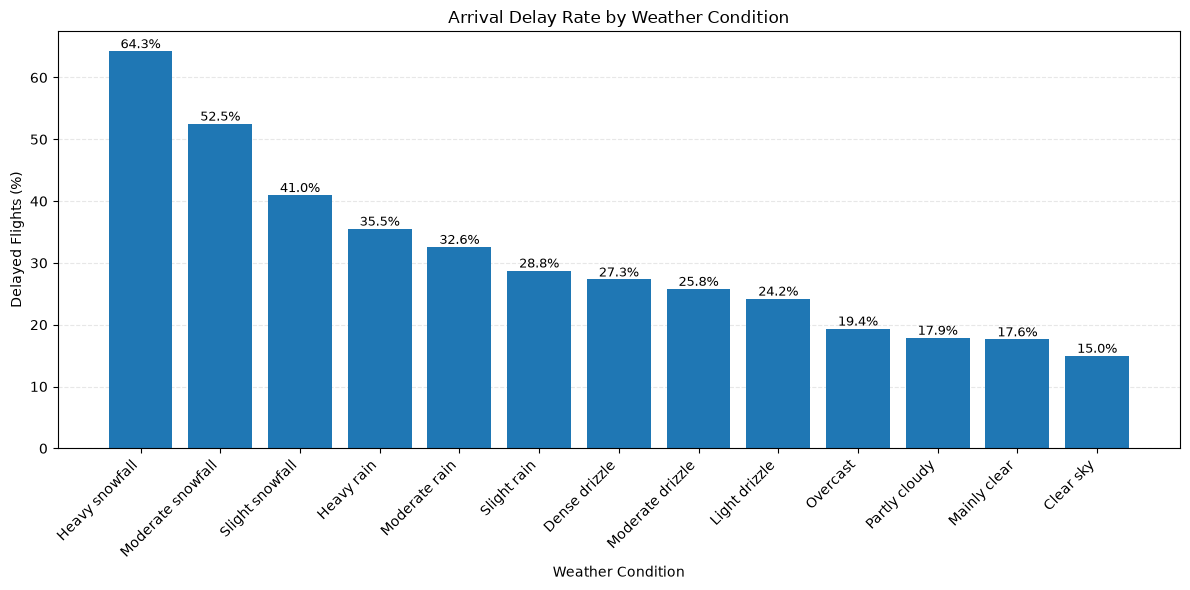

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    weather_delay_stats["WEATHER_CONDITION_NAME"],
    weather_delay_stats["DELAY_RATE_%"]
)

# Sütunların üzərində gecikmə faizlərini göstərək
for bar, rate in zip(bars, weather_delay_stats["DELAY_RATE_%"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title("Arrival Delay Rate by Weather Condition")
ax.set_xlabel("Weather Condition")
ax.set_ylabel("Delayed Flights (%)")
ax.tick_params(axis="x", rotation=45)
plt.xticks(ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Qarlı hava şəraiti ilə digər hava şəraiti göstəriciləri arasında statistik əhəmiyyətli fərqin olub-olmadığını yoxlayaq.

In [35]:
test_df = ml[
    ml["WEATHER_CONDITION"].notna()
    & ml["ARRIVAL_DELAY"].notna()
].copy()


In [36]:
# Qar kodları
snow_codes = [71, 73, 75]

In [37]:
# İki qrupun gəliş gecikmələri
snow_delays = test_df.loc[
    test_df["WEATHER_CONDITION"].isin(snow_codes),
    "ARRIVAL_DELAY"]

other_delays = test_df.loc[
    ~test_df["WEATHER_CONDITION"].isin(snow_codes),
    "ARRIVAL_DELAY"]


In [38]:
# Mann–Whitney U testi
u_stat, p_value = mannwhitneyu(
    snow_delays,
    other_delays,
    alternative="two-sided",
    method="asymptotic")

print("Qarlı hava uçuşlarının sayı:", len(snow_delays))
print("Digər hava şəraitində uçuşların sayı:", len(other_delays))

print("\nQarlı hava:")
print("Median gecikmə:", round(snow_delays.median(), 2), "dəqiqə")
print("Orta gecikmə:", round(snow_delays.mean(), 2), "dəqiqə")

print("\nDigər hava şəraiti:")
print("Median gecikmə:", round(other_delays.median(), 2), "dəqiqə")
print("Orta gecikmə:", round(other_delays.mean(), 2), "dəqiqə")

print(f"\nMann–Whitney U statistic: {u_stat:.2f}")
print(f"P-value: {p_value:.3e}")

if p_value < 0.05:
    print("Nəticə: İki qrupun gəliş gecikmələrinin paylanması arasında statistik əhəmiyyətli fərq var.")
else:
    print("Nəticə: Statistik əhəmiyyətli fərq üçün kifayət qədər sübut yoxdur.")

Qarlı hava uçuşlarının sayı: 12930
Digər hava şəraitində uçuşların sayı: 968585

Qarlı hava:
Median gecikmə: 11.0 dəqiqə
Orta gecikmə: 31.35 dəqiqə

Digər hava şəraiti:
Median gecikmə: -5.0 dəqiqə
Orta gecikmə: 4.03 dəqiqə

Mann–Whitney U statistic: 8504359358.50
P-value: 0.000e+00
Nəticə: İki qrupun gəliş gecikmələrinin paylanması arasında statistik əhəmiyyətli fərq var.


### Mann–Whitney U testi: Qarlı hava və digər hava şəraitləri

Qarlı hava şəraitində uçuşların gəliş gecikmələrinin digər hava şəraitlərindəki uçuşlarla müqayisədə fərqlənib-fərqlənmədiyini yoxlamaq üçün Mann–Whitney U testi aparılmışdır.

**Hipotezlər:**
- **H₀:** İki qrupun gəliş gecikmələrinin paylanması arasında fərq yoxdur.
- **H₁:** İki qrupun gəliş gecikmələrinin paylanması fərqlidir.

**Test nəticələri:**
- Qarlı hava üzrə uçuş sayı: **12,930**
- Digər hava şəraiti üzrə uçuş sayı: **968,585**
- Qarlı havada median gəliş gecikməsi: **11 dəqiqə**
- Digər hava şəraitində median gəliş gecikməsi: **−5 dəqiqə**
- Qarlı havada orta gəliş gecikməsi: **31.35 dəqiqə**
- Digər hava şəraitində orta gəliş gecikməsi: **4.03 dəqiqə**
- Mann–Whitney U statistic: **8,504,359,358.50**
- P-value: **p < 0.001**

**Şərh:**

P-value 0.05-dən kiçik olduğuna görə sıfır hipotezi rədd edilir. Beləliklə, qarlı və digər hava şəraitlərində uçuşların gəliş gecikmələrinin paylanması arasında statistik baxımdan əhəmiyyətli fərq mövcuddur.

Qarlı hava qrupunda median gecikmə 11 dəqiqə, digər hava şəraiti qrupunda isə −5 dəqiqədir. Orta gəliş gecikməsi də qarlı hava qrupunda xeyli yüksəkdir: 31.35 dəqiqə ilə müqayisədə 4.03 dəqiqə.

**Ümumi nəticə:** Bu datasetdə qarlı hava şəraitində uçuşlar daha yüksək gəliş gecikmələri ilə əlaqəlidir. Bununla belə, bu nəticə qarın gecikmələrə birbaşa səbəb olduğunu sübut etmir. Hava limanı, marşrut, mövsüm və digər amillər də nəticələrə təsir edə bilər.

## Addım 5. Outlier Analizi

5.1 IQR metodu ilə analiz

In [45]:
# Araşdıracağımız sütunlar
delay_columns = ["DEPARTURE_DELAY", "ARRIVAL_DELAY"]

In [48]:
outlier_results = []

for col in delay_columns:
    values = ml[col].dropna()

In [49]:
# Kvartillər və IQR
q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1


In [50]:
# Kənar dəyərlərin sərhədləri
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

In [ ]:
# Aşağı və yuxarı kənar dəyərlər
lower_outliers = values[values < lower_bound]
upper_outliers = values[values > upper_bound]

total_outliers = len(lower_outliers) + len(upper_outliers)

In [53]:
outlier_results.append({
        "COLUMN": col,
        "VALID_ROWS": len(values),
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "LOWER_BOUND": lower_bound,
        "UPPER_BOUND": upper_bound,
        "LOWER_OUTLIERS": len(lower_outliers),
        "UPPER_OUTLIERS": len(upper_outliers),
        "TOTAL_OUTLIERS": total_outliers,
        "OUTLIER_PERCENT_%": total_outliers / len(values) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,COLUMN,VALID_ROWS,Q1,Q3,IQR,LOWER_BOUND,UPPER_BOUND,LOWER_OUTLIERS,UPPER_OUTLIERS,TOTAL_OUTLIERS,OUTLIER_PERCENT_%
0,ARRIVAL_DELAY,981515,-13.0,8.0,21.0,-44.5,39.5,1632,86093,87725,8.94


## 2. Boxplot qrafikleri ilə Outlier analizi

C:\Users\user\AppData\Local\Temp\ipykernel_10344\3364839881.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\user\AppData\Local\Temp\ipykernel_10344\3364839881.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


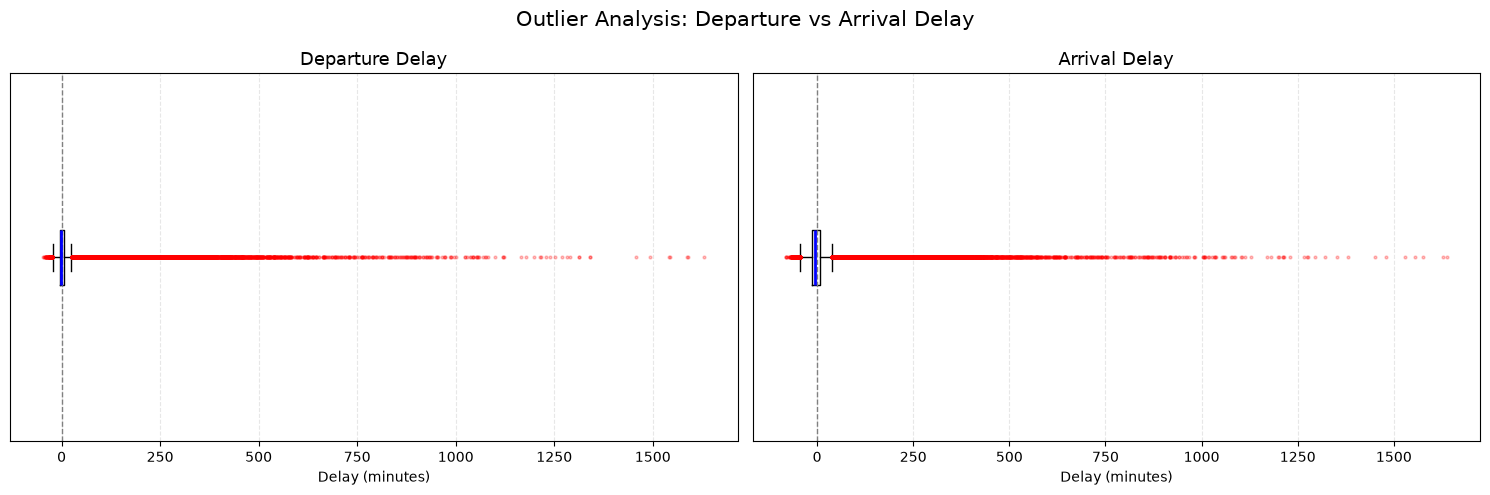

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

delay_columns = [
    ("DEPARTURE_DELAY", "Departure Delay"),
    ("ARRIVAL_DELAY", "Arrival Delay")
]

for ax, (col, title) in zip(axes, delay_columns):
    values = ml[col].dropna()

    ax.boxplot(
        values,
        vert=False,
        showfliers=True,
        flierprops=dict(
            marker="o",
            markersize=2,
            markerfacecolor="red",
            markeredgecolor="red",
            alpha=0.25
        ),
        medianprops=dict(color="blue", linewidth=2)
    )

    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Delay (minutes)")
    ax.set_yticks([])
    ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle(
    "Outlier Analysis: Departure vs Arrival Delay",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Outlier Analysis — Nəticələr

Gediş (`DEPARTURE_DELAY`) və gəliş (`ARRIVAL_DELAY`) gecikmələrində kənar dəyərləri müəyyən etmək üçün IQR (Interquartile Range) metodundan istifadə edilmişdir. Bu metodda Q1 − 1.5 × IQR-dən aşağı və Q3 + 1.5 × IQR-dən yuxarı olan müşahidələr kənar dəyər kimi müəyyən edilir.

**Əsas nəticələr:**

- **Gediş gecikməsi:** IQR sərhədləri −23 və 25 dəqiqədir. Ümumilikdə 126,365 müşahidə (12.83%) kənar dəyər kimi müəyyən edilmişdir.
- **Gəliş gecikməsi:** IQR sərhədləri −44.5 və 39.5 dəqiqədir. Ümumilikdə 87,725 müşahidə (8.94%) kənar dəyər kimi müəyyən edilmişdir.
- **Paylanma:** Hər iki qrafikdə sağ tərəfə uzanan uzun quyruq müşahidə olunur. Bu, az sayda uçuşda çox böyük gecikmələrin olduğunu və gecikmə paylanmasının sağa meyilli olduğunu göstərir.
- **Mənfi kənar dəyərlər:** Bunlar uçuşların planlaşdırılmış vaxtdan xeyli əvvəl başa çatmasını göstərə bilər; avtomatik olaraq səhv məlumat hesab edilməməlidir.

**Ümumi nəticə:** Hər iki gecikmə dəyişənində çoxsaylı kənar dəyərlər mövcuddur. Lakin bu müşahidələr mütləq məlumat xətası deyil və real ekstremal uçuş gecikmələrini əks etdirə bilər. Buna görə bu mərhələdə kənar dəyərlər silinməmiş, yalnız müəyyən edilərək təhlil edilmişdir. Sonrakı analizlərdə və Machine Learning mərhələsində onların modelə təsiri ayrıca qiymətləndiriləcək.

## Addım 6. Korelyasiya Analizi

In [55]:
correlation_cols = [
    "DEPARTURE_DELAY",
    "ARRIVAL_DELAY",
    "DISTANCE",
    "AIR_TIME",
    "TAXI_OUT",
    "TAXI_IN",
    "WEATHER_TEMPERATURE",
    "WEATHER_PRECIPITATION",
    "WEATHER_WIND_SPEED",
    "WEATHER_SURFACE_PRESSURE",
    "WEATHER_WIND_DIRECTION",
    "WEATHER_SNOWFALL",
    "WEATHER_WIND_GUSTS"]


In [56]:
# Yalnız DataFrame-də mövcud olan sütunlar
correlation_cols = [
    col for col in correlation_cols
    if col in ml.columns]


In [57]:
# Spearman korrelyasiya matrisi
corr_matrix = ml[correlation_cols].corr(method="spearman")

In [58]:
# Yalnız iki gecikmə sütununun əlaqələrini göstəririk
delay_corr = corr_matrix.loc[["DEPARTURE_DELAY", "ARRIVAL_DELAY"],correlation_cols]

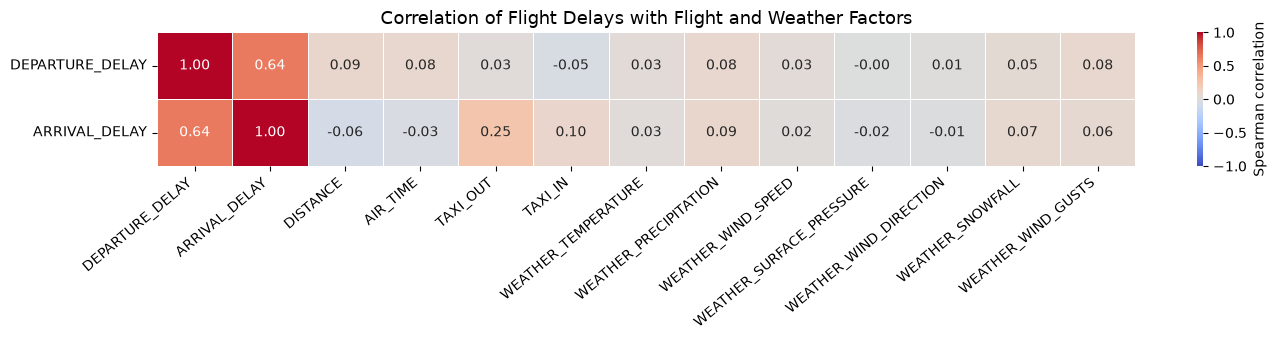

In [59]:
plt.figure(figsize=(14, 3.5))

sns.heatmap(
    delay_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation"}
)

plt.title(
    "Correlation of Flight Delays with Flight and Weather Factors",
    fontsize=13
)

plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Correlation Analysis — Nəticələr

Uçuş xüsusiyyətləri və hava şəraiti göstəricilərinin gediş və gəliş gecikmələri ilə əlaqəsini qiymətləndirmək üçün Spearman korrelyasiya analizi aparılmışdır.

**Əsas nəticələr:**

- `TAXI_OUT` gəliş gecikməsi ilə ən yüksək korrelyasiyaya malikdir (**ρ = 0.250**). Bu, müsbət, lakin güclü olmayan monoton əlaqəni göstərir.
- `DISTANCE` gediş gecikməsi ilə zəif müsbət əlaqə göstərir (**ρ = 0.092**).
- `WEATHER_PRECIPITATION` həm gediş (**ρ = 0.082**), həm də gəliş gecikməsi (**ρ = 0.087**) ilə zəif müsbət əlaqəyə malikdir.
- Külək sürəti, külək şiddəti, qar yağışı və temperatur göstəricilərinin gecikmələrlə korrelyasiyaları əsasən zəifdir.
- `WEATHER_SURFACE_PRESSURE` və `WEATHER_WIND_DIRECTION` ilə gecikmələr arasında monoton əlaqə çox zəif görünür.

**Ümumi nəticə:** Seçilmiş rəqəmsal dəyişənlər arasında `TAXI_OUT` gəliş gecikməsi ilə ən nəzərəçarpan əlaqəni göstərir. Hava şəraiti göstəricilərinin Spearman korrelyasiyaları isə əsasən zəifdir. Bununla belə, zəif korrelyasiya hava şəraitinin əhəmiyyətsiz olduğunu sübut etmir; qeyri-xətti və kateqoriyaya xas fərqləri ayrıca təhlil etmək lazımdır.



# Machine Learning

### Kitabxanaların yüklənməsi

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

### Yeni feature sütununu əlavə edilməsi



Öncəki reysin gecikib-gecikmediyini teyin etmək üçün xam datadan tail_number sütununu əlavə edirik

In [ ]:
df_sample = pd.read_parquet('/content/drive/MyDrive/flights_sample (1).parquet')

In [ ]:
month_name_map = {
    1: 'January', 2: 'February', 3: 'March', 4: 'April',
    5: 'May', 6: 'June', 7: 'July', 8: 'August',
    9: 'September', 10: 'October', 11: 'November', 12: 'December'}
df_sample['MONTH'] = df_sample['MONTH'].map(month_name_map)

In [ ]:
# Xam datadakı saatları (1233 -> '12:33:00') formatına çevirmək üçün funksiya
def format_time_to_hhmmss(val):
    if pd.isna(val):
        return None
    # 4 rəqəmli formata salırıq (məs: 5 -> '0005', 730 -> '0730', 1815 -> '1815')
    s = f"{int(val):04d}"
    return f"{s[:2]}:{s[2:]}:00"

df_sample['SCHEDULED_DEPARTURE'] = df_sample['SCHEDULED_DEPARTURE'].apply(format_time_to_hhmmss)
df_sample['SCHEDULED_ARRIVAL'] = df_sample['SCHEDULED_ARRIVAL'].apply(format_time_to_hhmmss)

In [ ]:
join_keys = [
    'MONTH',
    'DAY',
    'DAY_OF_WEEK',
    'AIRLINE',
    'ORIGIN_AIRPORT',
    'DESTINATION_AIRPORT',
    'SCHEDULED_DEPARTURE',
    'SCHEDULED_ARRIVAL']


In [ ]:
#  Bütün açarların tiplərini dəqiq eyniləşdiririk
for col in join_keys:
    df_sample[col] = df_sample[col].astype(str)
    ml[col] = ml[col].astype(str)

In [ ]:
#  Xam datada təkrarları təmizləyirik
sample_tail = df_sample[join_keys + ['TAIL_NUMBER']].drop_duplicates(subset=join_keys)

In [ ]:
#  Left join ilə TAIL_NUMBER-i əlavə edirik
ml_updated = ml.merge(
    sample_tail,
    on=join_keys,
    how='left')


In [ ]:
print(f"Silver sətir sayı: {len(ml_updated)}")
print(f"Tapılan TAIL_NUMBER sayı: {ml_updated['TAIL_NUMBER'].notna().sum()}")

Silver sətir sayı: 999657
Tapılan TAIL_NUMBER sayı: 997076


In [ ]:
# TAIL_NUMBER tapılmayan sətirlərin statusu
missing_tail = ml_updated[ml_updated['TAIL_NUMBER'].isna()]
print("Ləğv olunmuş reyslərin sayı (CANCELLED):", missing_tail['CANCELLED'].sum())
print("Yönləndirilmiş reyslərin sayı (DIVERTED):", missing_tail['DIVERTED'].sum())

Ləğv olunmuş reyslərin sayı (CANCELLED): 2581
Yönləndirilmiş reyslərin sayı (DIVERTED): 0


2581 boş tail_number ləğv edilmiş uçuşlara aiddir.

In [ ]:
# 1. Ay adlarını rəqəmə çevirmək üçün xəritə
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12}


In [ ]:
if ml_updated['MONTH'].dtype == 'object':
    ml_updated['MONTH_NUM'] = ml_updated['MONTH'].map(month_map).fillna(ml_updated['MONTH']).astype(int)
else:
    ml_updated['MONTH_NUM'] = ml_updated['MONTH'].astype(int)

In [ ]:
# 2. Xronoloji ardıcıllıq üçün dəqiq uçuş vaxtını (Datetime) yaradırıq
ml_updated['FLIGHT_DATETIME'] = pd.to_datetime(
    ml_updated['YEAR'].astype(str) + '-' +
    ml_updated['MONTH_NUM'].astype(str) + '-' +
    ml_updated['DAY'].astype(str) + ' ' +
    ml_updated['SCHEDULED_DEPARTURE'].astype(str),
    errors='coerce')


In [ ]:
# TAIL_NUMBER və uçuş vaxtına görə sıralayırıq
ml_updated = ml_updated.sort_values(by=['TAIL_NUMBER', 'FLIGHT_DATETIME']).reset_index(drop=True)

In [ ]:
#  Hər təyyarə üzrə əvvəlki reysin məlumatlarını gətiririk:

# Gecikmə: Əvvəlki reys gecikmişdimi? (1 = Bəli, 0 = Xeyr)
ml_updated['PREV_FLIGHT_IS_DELAYED'] = ml_updated.groupby('TAIL_NUMBER')['IS_DELAYED'].shift(1)

# Gecikmə müddəti: Əvvəlki reys neçə dəqiqə gecikmişdi? (Arrival delay)
ml_updated['PREV_ARRIVAL_DELAY'] = ml_updated.groupby('TAIL_NUMBER')['ARRIVAL_DELAY'].shift(1)

In [ ]:
# 5. Boş qalan dəyərləri (NaN) doldururuq:
# Təyyarənin həmin dövr üçün İLK reysinin əvvəlki reysi olmadığı üçün NaN qalır.
# Model üçün bu sətirləri 0 ilə doldura bilərsiniz (gecikmə olmayıb kimi qəbul edilir):
ml_updated['PREV_FLIGHT_IS_DELAYED'] = ml_updated['PREV_FLIGHT_IS_DELAYED'].fillna(0).astype(int)
ml_updated['PREV_ARRIVAL_DELAY'] = ml_updated['PREV_ARRIVAL_DELAY'].fillna(0)


In [ ]:
ml_updated.head()

,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,DISTANCE,SCHEDULED_DEPARTURE,SCHEDULED_ARRIVAL,DEPARTURE_DELAY,...,FLIGHT_STATUS,IS_WEEKEND,DEPARTURE_PERIOD,IS_LONG_DISTANCE,WEATHER_CONDITION_NAME,TAIL_NUMBER,MONTH_NUM,FLIGHT_DATETIME,PREV_FLIGHT_IS_DELAYED,PREV_ARRIVAL_DELAY
0,July,11,6,WN,STL,ATL,484,12:00:00,14:35:00,-4.0,...,Completed,1,Afternoon,0,Overcast,7819A,7,2015-07-11 12:00:00,0,0.0
1,July,11,6,WN,MSY,DEN,1062,18:25:00,20:15:00,125.0,...,Completed,1,Evening,0,Clear sky,7819A,7,2015-07-11 18:25:00,0,-15.0
2,July,11,6,WN,DEN,OAK,957,21:10:00,22:45:00,95.0,...,Completed,1,Evening,0,Clear sky,7819A,7,2015-07-11 21:10:00,1,104.0
3,July,13,1,WN,LGA,DAL,1381,06:55:00,09:45:00,-9.0,...,Completed,0,Morning,0,Overcast,7819A,7,2015-07-13 06:55:00,1,88.0
4,July,13,1,WN,LAX,OAK,337,13:30:00,14:45:00,-2.0,...,Completed,0,Afternoon,0,Clear sky,7819A,7,2015-07-13 13:30:00,0,-42.0


Tail_number sütunundan istifadə edərək hər reysdən əvvəlki reysin gecikib-gecikmədiyini müəyyən edən sütunlar yaratdıq.

Planlaşdırılmış uçuş vaxtından saat sütununu çıxarırıq. Bunu ona görə etməliyik ki, Sheduled_Departure sütununda məlumatlar object kimi saxlanılır, bizim modelimiz isə riyazi tiplərlə işləyir.

In [ ]:
ml_updated["DEP_HOUR"] = pd.to_datetime(
    ml_updated["SCHEDULED_DEPARTURE"].astype(str), format="%H:%M:%S").dt.hour

In [ ]:
ml_updated.head()

,MONTH,DAY,DAY_OF_WEEK,AIRLINE,ORIGIN_AIRPORT,DESTINATION_AIRPORT,DISTANCE,SCHEDULED_DEPARTURE,SCHEDULED_ARRIVAL,DEPARTURE_DELAY,...,IS_WEEKEND,DEPARTURE_PERIOD,IS_LONG_DISTANCE,WEATHER_CONDITION_NAME,TAIL_NUMBER,MONTH_NUM,FLIGHT_DATETIME,PREV_FLIGHT_IS_DELAYED,PREV_ARRIVAL_DELAY,DEP_HOUR
0,July,11,6,WN,STL,ATL,484,12:00:00,14:35:00,-4.0,...,1,Afternoon,0,Overcast,7819A,7,2015-07-11 12:00:00,0,0.0,12
1,July,11,6,WN,MSY,DEN,1062,18:25:00,20:15:00,125.0,...,1,Evening,0,Clear sky,7819A,7,2015-07-11 18:25:00,0,-15.0,18
2,July,11,6,WN,DEN,OAK,957,21:10:00,22:45:00,95.0,...,1,Evening,0,Clear sky,7819A,7,2015-07-11 21:10:00,1,104.0,21
3,July,13,1,WN,LGA,DAL,1381,06:55:00,09:45:00,-9.0,...,0,Morning,0,Overcast,7819A,7,2015-07-13 06:55:00,1,88.0,6
4,July,13,1,WN,LAX,OAK,337,13:30:00,14:45:00,-2.0,...,0,Afternoon,0,Clear sky,7819A,7,2015-07-13 13:30:00,0,-42.0,13


## Feature və Target təyini

In [ ]:
lr = ml_updated[ml_updated["IS_DELAYED"].notna()].copy()
lr["IS_DELAYED"] = lr["IS_DELAYED"].astype(int)

In [ ]:
lr.shape

In [ ]:
features = [
    'DISTANCE',
    'DEP_HOUR',
    'WEATHER_SURFACE_PRESSURE',
    'WEATHER_WIND_DIRECTION',
    'WEATHER_SNOWFALL',
    'WEATHER_WIND_GUSTS',
    'AIRLINE',
    'MONTH',
    'DAY_OF_WEEK',
    'WEATHER_CONDITION_NAME',
    'IS_WEEKEND',
    'IS_LONG_DISTANCE',
    'PREV_FLIGHT_IS_DELAYED',
    'ORIGIN_AIRPORT',
    'DESTINATION_AIRPORT'
]

X = lr[features].copy()
y = lr['IS_DELAYED'].copy()

print("X ölçüsü:", X.shape)
print("y ölçüsü:", y.shape)

X ölçüsü: (981515, 15)
y ölçüsü: (981515,)


In [ ]:
# Hədəf dəyişənin paylanması
print(y.value_counts(dropna=False))
print("\nHədəf faizləri:")
print((y.value_counts(normalize=True, dropna=False) * 100).round(2))

# Seçilmiş xüsusiyyətlərdə boş dəyərlər
print("\nBoş dəyərlərin sayı:")
print(X.isnull().sum().sort_values(ascending=False))

IS_DELAYED
0    798989
1    182526
Name: count, dtype: int64

Hədəf faizləri:
IS_DELAYED
0    81.4
1    18.6
Name: proportion, dtype: float64

Boş dəyərlərin sayı:
DISTANCE                    0
DEP_HOUR                    0
WEATHER_SURFACE_PRESSURE    0
WEATHER_WIND_DIRECTION      0
WEATHER_SNOWFALL            0
WEATHER_WIND_GUSTS          0
AIRLINE                     0
MONTH                       0
DAY_OF_WEEK                 0
WEATHER_CONDITION_NAME      0
IS_WEEKEND                  0
IS_LONG_DISTANCE            0
PREV_FLIGHT_IS_DELAYED      0
ORIGIN_AIRPORT              0
DESTINATION_AIRPORT         0
dtype: int64


## Train & Test

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (785212, 15)
X_test: (196303, 15)
y_train: (785212,)
y_test: (196303,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


In [ ]:
# Rəqəmsal dəyərlər
numeric_features = [
    'DISTANCE',
    'DEP_HOUR',
    'WEATHER_SURFACE_PRESSURE',
    'WEATHER_WIND_DIRECTION',
    'WEATHER_SNOWFALL',
    'WEATHER_WIND_GUSTS',
    'DAY_OF_WEEK',
    'IS_WEEKEND',
    'IS_LONG_DISTANCE',
    'PREV_FLIGHT_IS_DELAYED']

In [ ]:
# Kateqorik xüsusiyyətlər
categorical_features = [
    'AIRLINE',
    'WEATHER_CONDITION_NAME',
    'MONTH','ORIGIN_AIRPORT','DESTINATION_AIRPORT']

In [ ]:
# Rəqəmsal məlumatların hazırlanması
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [ ]:
# Kateqorik məlumatların hazırlanması
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [ ]:
# Çevirmələri birləşdiririk
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

## XGBOOST model



In [ ]:
pip install xgboost

In [ ]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

# Model creation
xgb_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=150,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=4.38,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

# Training
xgb_pipeline.fit(X_train, y_train)

# Prediction
y_prob_xgb = xgb_pipeline.predict_proba(X_test)[:, 1]
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

# Evaluation
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("ROC AUC:", round(roc_auc_score(y_test, y_prob_xgb), 4))
print("PR AUC:", round(average_precision_score(y_test, y_prob_xgb), 4))

Confusion Matrix:
[[106244  53554]
 [ 13645  22860]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.66      0.76    159798
           1       0.30      0.63      0.40     36505

    accuracy                           0.66    196303
   macro avg       0.59      0.65      0.58    196303
weighted avg       0.78      0.66      0.69    196303

ROC AUC: 0.7023
PR AUC: 0.375


In [ ]:
depth_values = [4, 6, 8]
depth_results = []

for depth in depth_values:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=150,
            max_depth=depth,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=4.38,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    depth_results.append({
        'Max Depth': depth,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(y_test, probabilities)
    })

pd.DataFrame(depth_results).round(4)

In [ ]:
learning_values = [0.03, 0.05, 0.1]

learning_results = []

for rate in learning_values:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=150,
            max_depth=8,
            learning_rate=rate,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=4.38,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    learning_results.append({
        'Learning Rate': rate,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(y_test, probabilities)
    })

pd.DataFrame(learning_results).round(4)

In [ ]:
tree_values = [150, 250, 350]
tree_results = []

for trees in tree_values:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=trees,
            max_depth=8,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=4.38,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    tree_results.append({
        'N Estimators': trees,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(y_test, probabilities)
    })

pd.DataFrame(tree_results).round(4)

In [ ]:
subsample_values = [0.7, 0.8, 1.0]
subsample_results = []

for sample in subsample_values:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=350,
            max_depth=8,
            learning_rate=0.1,
            subsample=sample,
            colsample_bytree=0.8,
            scale_pos_weight=4.38,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    subsample_results.append({
        'Subsample': sample,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(y_test, probabilities)
    })

pd.DataFrame(subsample_results).round(4)

In [ ]:
colsample_values = [0.6, 0.8, 1.0]
colsample_results = []

for colsample in colsample_values:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=350,
            max_depth=8,
            learning_rate=0.1,
            subsample=0.7,
            colsample_bytree=colsample,
            scale_pos_weight=4.38,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    colsample_results.append({
        'Colsample Bytree': colsample,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(y_test, probabilities)
    })

pd.DataFrame(colsample_results).round(4)

In [ ]:
weight_values = [3.5, 4.38, 5.0]
weight_results = []

for weight in weight_values:

    model = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(
            n_estimators=350,
            max_depth=8,
            learning_rate=0.1,
            subsample=0.7,
            colsample_bytree=0.8,
            scale_pos_weight=weight,
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss'
        ))
    ])

    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    weight_results.append({
        'Scale Pos Weight': weight,
        'Precision': precision_score(y_test, predictions),
        'Recall': recall_score(y_test, predictions),
        'F1': f1_score(y_test, predictions),
        'ROC AUC': roc_auc_score(y_test, probabilities),
        'PR AUC': average_precision_score(y_test, probabilities)
    })

pd.DataFrame(weight_results).round(4)

In [ ]:
best_xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=350,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.7,
        colsample_bytree=0.8,
        scale_pos_weight=3.5,
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss'
    ))
])

best_xgb.fit(X_train, y_train)

y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = (y_prob_xgb >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

print("ROC AUC:", round(roc_auc_score(y_test, y_prob_xgb), 4))
print("PR AUC:", round(average_precision_score(y_test, y_prob_xgb), 4))

Confusion Matrix:
[[126701  33097]
 [ 17944  18561]]

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.79      0.83    159798
           1       0.36      0.51      0.42     36505

    accuracy                           0.74    196303
   macro avg       0.62      0.65      0.63    196303
weighted avg       0.78      0.74      0.76    196303

ROC AUC: 0.7167
PR AUC: 0.3974


Model:
- 18,561 gecikən uçuşu düzgün müəyyən edib.
- 17,944 gecikən uçuşu qaçırıb.
- 33,097 uçuşa səhvən gecikmə proqnozu verib.
Əvvəlki scale_pos_weight=4.38 variantı ilə müqayisədə:
- Precision: 0.3168 → 0.3593
- Recall: 0.6219 → 0.5085
- F1: 0.4198 → 0.4211

In [ ]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Train:", X_train_new.shape)
print("Validation:", X_val.shape)

Train: (628169, 15)
Validation: (157043, 15)


In [ ]:
best_xgb.fit(X_train_new, y_train_new)

y_val_prob = best_xgb.predict_proba(X_val)[:, 1]

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

results = []

for t in thresholds:
    y_val_pred = (y_val_prob >= t).astype(int)

    results.append({
        "Threshold": t,
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1": f1_score(y_val, y_val_pred)
    })

pd.DataFrame(results).round(4)

,Threshold,Precision,Recall,F1
0,0.25,0.2174,0.9288,0.3523
1,0.30,0.2363,0.8710,0.3718
2,0.35,0.2598,0.7992,0.3921
3,0.40,0.2876,0.7107,0.4095
4,0.45,0.3209,0.6128,0.4212
5,0.50,0.3592,0.5069,0.4204
6,0.55,0.4020,0.4057,0.4039
7,0.60,0.4437,0.3140,0.3678


0.45: F1 ən yüksəkdir – 0.4212.



0.50: Precision daha yüksəkdir – 0.3592, amma Recall aşağıdır – 0.5069.



0.40: Recall daha yüksəkdir – 0.7107, amma Precision aşağıdır – 0.2876.


In [ ]:
optimal_threshold = 0.45

y_val_pred = (y_val_prob >= optimal_threshold).astype(int)

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

y_test_prob = best_xgb.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_prob >= 0.45).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("ROC AUC:", roc_auc_score(y_test, y_test_prob))
print("PR AUC:", average_precision_score(y_test, y_test_prob))

Confusion Matrix:
[[112126  47672]
 [ 14283  22222]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.70      0.78    159798
           1       0.32      0.61      0.42     36505

    accuracy                           0.68    196303
   macro avg       0.60      0.66      0.60    196303
weighted avg       0.78      0.68      0.72    196303

ROC AUC: 0.7145309066482216
PR AUC: 0.3945470183990214


Threshold 0.45 olduqda:
- 36,505 gecikmiş uçuşdan 22,222-ni düzgün aşkarlayır.
- 14,283 gecikmiş uçuşu qaçırır.
- 47,672 uçuşa gecikmə xəbərdarlığı verir, amma onlar əslində gecikməyib.

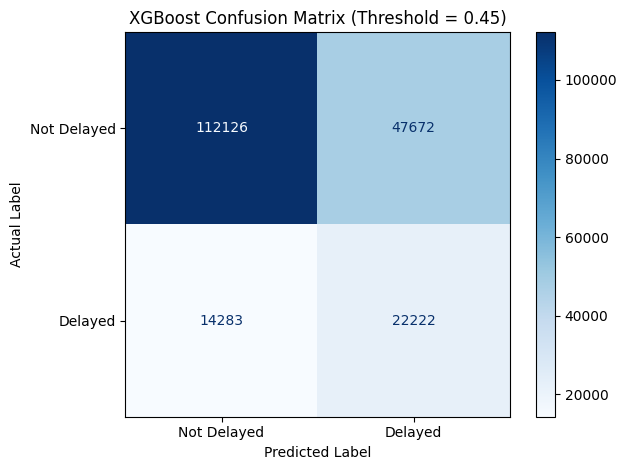

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Delayed', 'Delayed']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('XGBoost Confusion Matrix (Threshold = 0.45)')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

In [ ]:
import joblib
from google.colab import files

# Save complete pipeline
joblib.dump(
    best_xgb,
    "xgboost_flight_delay_pipeline.joblib",
    compress=3
)

# Save threshold
joblib.dump(
    0.45,
    "optimal_threshold.pkl"
)

# Download files
files.download("xgboost_flight_delay_pipeline.joblib")
files.download("optimal_threshold.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import xgboost
import sklearn

print("XGBoost:", xgboost.__version__)
print("Scikit-learn:", sklearn.__version__)

print("Pipeline:", type(best_xgb))
print("Classifier:", type(best_xgb.named_steps["classifier"]))

XGBoost: 3.4.1
Scikit-learn: 1.6.1
Pipeline: <class 'sklearn.pipeline.Pipeline'>
Classifier: <class 'xgboost.sklearn.XGBClassifier'>


In [ ]:
import joblib
from google.colab import files

# 1. Preprocessing hissəsini saxla
joblib.dump(
    best_xgb.named_steps["preprocessor"],
    "flight_preprocessor.joblib"
)

# 2. XGBoost modelini JSON formatında saxla
best_xgb.named_steps["classifier"].save_model(
    "flight_xgboost.json"
)

# 3. Threshold-u saxla
joblib.dump(0.45, "optimal_threshold.pkl")

# 4. Faylları endir
files.download("flight_preprocessor.joblib")
files.download("flight_xgboost.json")
files.download("optimal_threshold.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>